In [1]:
from rdkit import Chem
import pickle
import os
import json
import numpy as np
import xgboost
import sys

from shared.ml_helper import make_fingerprint # pyright: ignore[reportMissingImports]
from matplotlib import pyplot as plt
from cycler import cycler

from matplotlib.colors import ListedColormap
import numpy as np

# Example: define your own RGB color palette
# Replace these tuples with your desired RGB codes (values between 0 and 1)
custom_colors = [
    (169, 27, 46),  # blue-ish
    (0, 138, 173),  # red-ish
    (0, 48, 136),  # green-ish
    (138, 26, 155),  # yellow-ish
    (240, 137, 0)   # purple-ish
]

custom_c = [ tuple(c[i] / 256.0 for i in range(3)) for c in custom_colors ]

custom_cmap = ListedColormap(custom_c)
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}

In [2]:
# Data analysis



arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: '-H+ to bond',
    9: '-H+ to atom',
    10: 'elimination to bond'
}


training_dir = "training_sets/20260202"


# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors = []
outcomes = []
contributors = {}
count_dirs = 0
count_arrows = 0

for subdir in subdirs:
    count_dirs += 1
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {pkl_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    contributor = data.get('contributor')
    if contributor in contributors or None in contributors:
        if contributor == '':
             contributors[None] += 1
        else:
            contributors[contributor] += 1
    else:
        if contributor == '':
             contributors[None] = 1
        else:
            contributors[contributor] = 1
    for id, info in choices.items():
        # bitvector for the mechanism
        if info['probable'] is None:
            continue
        try:
            sum_finger_print = make_fingerprint(sm, info['mechanism'])
        except:
             print(f"Error processing {training_dir}/{subdir} mechanism {info['mechanism']}")
        bitvectors.append(sum_finger_print)
        
        count_arrows += 1
        outcomes.append(info['probable'])
        # Track the origin of each bitvector
        with open("bitvector_origins.txt", "a") as origin_file:
            origin_file.write(f"{len(bitvectors)-1},{training_dir}/{subdir},{id}\n")


print(f"total directories: {count_dirs}, total arrows: {count_arrows}")
# with open(f'{training_dir}/bitvectors.csv', 'w', newline='') as csvfile:
#     writer = csv.writer(csvfile)
#     for bv, outcome in zip(bitvectors, outcomes):
#         writer.writerow(bv + [outcome])

[16:40:27] 

****
Range Error
idx
Violation occurred on line 198 in file /home/conda/feedstock_root/build_artifacts/rdkit-meta_1767159473677/work/Code/GraphMol/ROMol.cpp
Failed Expression: 11 < 11
----------
Stacktrace:
 0# Invar::Invariant::toString[abi:cxx11]() const in /home/rd611/.conda/envs/aim/lib/python3.13/site-packages/rdkit/../../../libRDKitRDGeneral.so.1
 1# Invar::operator<<(std::ostream&, Invar::Invariant const&) in /home/rd611/.conda/envs/aim/lib/python3.13/site-packages/rdkit/../../../libRDKitRDGeneral.so.1
 2# RDKit::ROMol::getAtomWithIdx(unsigned int) in /home/rd611/.conda/envs/aim/lib/python3.13/site-packages/rdkit/Chem/../../../../libRDKitGraphMol.so.1
 3# 0x00007FDB52F6B2E4 in /home/rd611/.conda/envs/aim/lib/python3.13/site-packages/rdkit/Chem/rdchem.so
 4# boost::python::objects::function::call(_object*, _object*) const in /home/rd611/.conda/envs/aim/lib/python3.13/site-packages/rdkit/../../../libboost_python313.so.1.86.0
 5# 0x00007FDBB40437A9 in /home/rd611/.cond

Error processing training_sets/20260202/60 mechanism [4, 5, 11, None, None]
Error processing training_sets/20260202/60 mechanism [4, 6, 11, None, None]
Error processing training_sets/20260202/60 mechanism [9, 11, 7, 8, None]
Error processing training_sets/20260202/60 mechanism [0, 11, 8, None, None]
Error processing training_sets/20260202/60 mechanism [9, 11, 10, 8, None]
Error processing training_sets/20260202/60 mechanism [1, 5, 10, None, 11]
Error processing training_sets/20260202/60 mechanism [1, 6, 10, None, 11]
Error processing training_sets/20260202/60 mechanism [1, 11, 4, None, 5]
total directories: 403, total arrows: 9486


In [3]:
# Data analysis



import csv


arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: '-H+ to bond',
    9: '-H+ to atom',
    10: 'elimination to bond'
}


training_dir = "finetuning_combined"


# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors_finetuning = []
outcomes_finetuning = []

count_dirs_finetuning = 0
count_arrows_finetuning = 0

for subdir in subdirs:
    count_dirs_finetuning += 1
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {pkl_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    
    for id, info in choices.items():
        # bitvector for the mechanism
        if info['probable'] is None:
            continue
        try:
            sum_finger_print = make_fingerprint(sm, info['mechanism'])
        except Exception as e:
             print(f"Error processing {training_dir}/{subdir} mechanism {info['mechanism']}: {e}")
        bitvectors_finetuning.append(sum_finger_print)
        
        count_arrows_finetuning += 1
        outcomes_finetuning.append(info['probable'])
        # Track the origin of each bitvector
        with open("bitvector_origins.txt", "a") as origin_file:
            origin_file.write(f"{len(bitvectors_finetuning)-1},{training_dir}/{subdir},{id}\n")


print(f"total directories: {count_dirs_finetuning}, total arrows: {count_arrows_finetuning}")
with open(f'{training_dir}/bitvectors.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    for bv, outcome in zip(bitvectors_finetuning, outcomes_finetuning):
        writer.writerow(bv + [outcome])

total directories: 21, total arrows: 63


In [86]:
contributors

{'Richard': 263, None: 140}

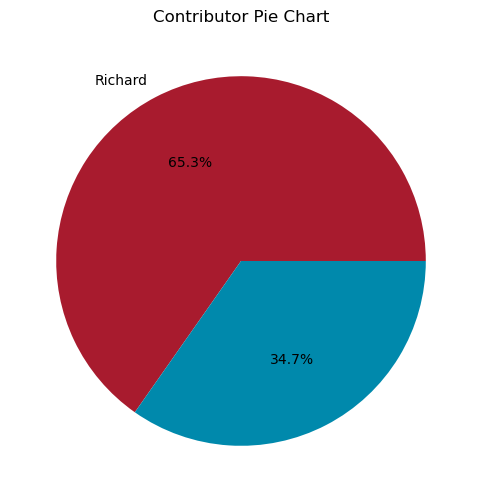

In [87]:
plt.figure(figsize=(6, 6))
plt.pie(list(contributors.values()), labels=list(contributors.keys()), autopct='%1.1f%%', colors=custom_c[:len(contributors)])
plt.title("Contributor Pie Chart")
plt.show()

In [88]:
set_bitvectors = set(tuple(bv) for bv in bitvectors)
print(f"Total unique bitvectors: {len(set_bitvectors)}")
print(f"Total bitvectors: {len(bitvectors)}")
# with open("unique_bitvectors.txt", "w") as ubv_file:
#     for bv in set_bitvectors:
#         ubv_file.write(','.join(map(str, bv)) + '\n')


Total unique bitvectors: 6142
Total bitvectors: 9486


folder: training_sets/20260202/307
choice id: 0
probable: 0
mechanism: [8, 2, 0, 1, 2]
starting SMILES: CC#N.CC1([OH2+])CCCCC1.O
product SMILES: C=C=N.CC1([OH2+])CCCCC1.O


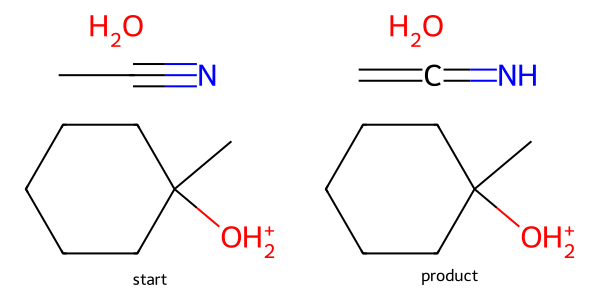

In [19]:
import random, os, json, pickle
from rdkit import Chem
from rdkit.Chem import Draw

# pick a random training folder and a random choice inside it
subdir = np.random.choice(subdirs)
folder = os.path.join(training_dir, subdir)

with open(os.path.join(folder, "data.json"), "r") as f:
    data = json.load(f)

choices = data.get("choices", {})
if not choices:
    raise RuntimeError(f"No choices found in {folder}")

choice_id = random.choice(list(choices.keys()))
info = choices[choice_id]

# load starting molecule
sm_path = os.path.join(folder, "sm.pkl")
with open(sm_path, "rb") as f:
    sm = pickle.load(f)

# try to load the molecule file corresponding to this choice (if present)
mol_path = os.path.join(folder, f"mol_{choice_id}.pkl")
prod = None
if os.path.exists(mol_path):
    with open(mol_path, "rb") as f:
        prod = pickle.load(f)

# print summary
print("folder:", folder)
print("choice id:", choice_id)
print("probable:", info.get("probable"))
print("mechanism:", info.get("mechanism"))

print("starting SMILES:", Chem.MolToSmiles(sm) if sm is not None else None)
if prod is not None:
    print("product SMILES:", Chem.MolToSmiles(prod))
else:
    print("product SMILES: (mol file not found)")

# display molecules inline if RDKit drawing is available
mols = [m for m in (sm, prod) if m is not None]
legends = ["start"] + (["product"] if prod is not None else [])
if mols:
    disp = Draw.MolsToGridImage(mols, molsPerRow=len(mols), subImgSize=(300, 300), legends=legends)
    display(disp)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, recall_score, precision_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay, auc

In [90]:
#Cheating
bitvectors = bitvectors + bitvectors
outcomes = outcomes + outcomes

In [18]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

# Logistic Regression classifier
clf = LogisticRegression()
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))
#joblib.dump(clf, 'model.pkl')

Accuracy: 0.9152613827993255
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.97      0.95      1989
           1       0.79      0.65      0.71       383

    accuracy                           0.92      2372
   macro avg       0.86      0.81      0.83      2372
weighted avg       0.91      0.92      0.91      2372



In [5]:
from xgboost import XGBClassifier

In [13]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)

ratio = len(outcomes)/sum(outcomes)
print(ratio)

# XGBoost Regression classifier
clf = XGBClassifier(scale_pos_weight = 7, eval_metric='logloss', max_depth=10)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
#joblib.dump(clf, 'models/v13/xg_model.pkl')
#clf.save_model('models/v81/xg_model.json')

6.596662030598053
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      2004
           1       0.77      0.85      0.81       368

    accuracy                           0.94      2372
   macro avg       0.87      0.90      0.89      2372
weighted avg       0.94      0.94      0.94      2372



In [6]:
weighting = 5

bitvectors_new = bitvectors + bitvectors_finetuning * weighting
outcomes_new = outcomes + outcomes_finetuning * weighting

X_train, X_test, y_train, y_test = train_test_split(bitvectors_new, outcomes_new, test_size=0.25)

ratio = len(outcomes_new)/sum(outcomes_new)
print(ratio)

# XGBoost Regression classifier
clf = XGBClassifier(scale_pos_weight = 7, eval_metric='logloss', max_depth=10)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
#joblib.dump(clf, 'models/v13/xg_model.pkl')
clf.save_model('models/v82f2/xg_model.json')

6.2110266159695815
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      2043
           1       0.78      0.87      0.82       408

    accuracy                           0.94      2451
   macro avg       0.88      0.91      0.89      2451
weighted avg       0.94      0.94      0.94      2451



Exception ignored on calling ctypes callback function <bound method DataIter._next_wrapper of <xgboost.data.SingleBatchInternalIter object at 0x7f99699e3540>>:
Traceback (most recent call last):
  File "/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/xgboost/core.py", line 616, in _next_wrapper
    return self._handle_exception(lambda: int(self.next(input_data)), 0)
  File "/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/xgboost/core.py", line 529, in _handle_exception
    return fn()
  File "/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/xgboost/core.py", line 616, in <lambda>
    return self._handle_exception(lambda: int(self.next(input_data)), 0)
  File "/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/xgboost/data.py", line 1654, in next
    input_data(**self.kwargs)
  File "/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/xgboost/core.py", line 705, in inner_f
    return func(**kwargs)
  File "/home/rd611/.conda/envs/aim/lib/python3.13/s

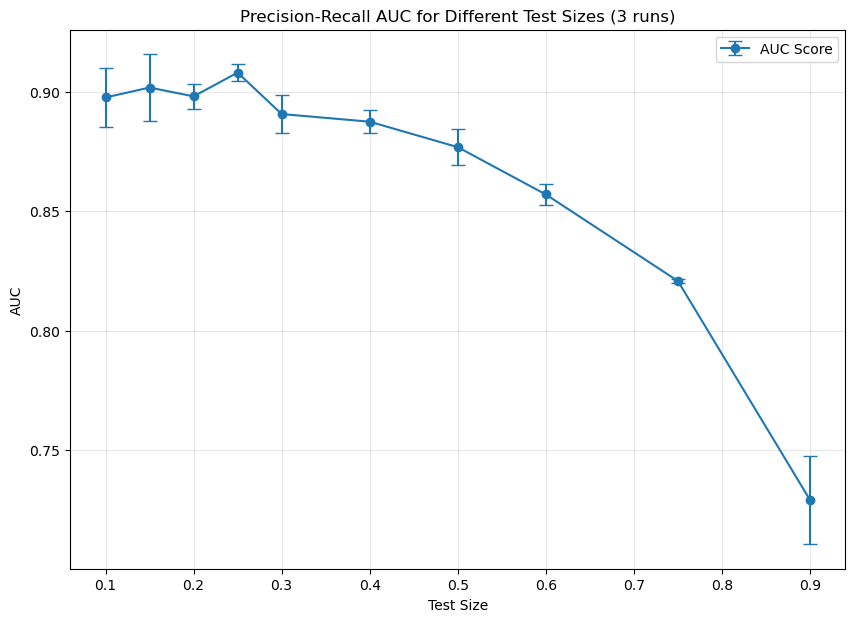

In [19]:
from sklearn.metrics import precision_recall_curve, auc

test_sizes = [0.9, 0.75, 0.6, 0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1]
auc_scores = {ts: [] for ts in test_sizes}

# Three training runs for each test size
for run in range(3):
    for test_size in test_sizes:
        X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=test_size)
        
        clf = XGBClassifier(scale_pos_weight=7, eval_metric='logloss', max_depth=10)
        clf.fit(X_train, y_train)
        
        y_pred_proba = clf.predict_proba(X_test)[:, 1]
        precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
        auc_score = auc(recall, precision)
        auc_scores[test_size].append(auc_score)

# Calculate means and standard deviations
means = [np.mean(auc_scores[ts]) for ts in test_sizes]
stds = [np.std(auc_scores[ts]) for ts in test_sizes]

plt.figure(figsize=(10, 7))
plt.errorbar(test_sizes, means, yerr=stds, marker='o', capsize=5, label='AUC Score')
plt.xlabel('Test Size')
plt.ylabel('AUC')
plt.title('Precision-Recall AUC for Different Test Sizes (3 runs)')
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.show()

In [12]:
y_pred_proba = clf.predict_proba(X_test)[:, 1]
y_pred_proba 


array([7.8464970e-02, 8.8282883e-01, 9.9567896e-01, ..., 2.1471612e-02,
       9.0670532e-05, 3.7562725e-06], shape=(3076,), dtype=float32)

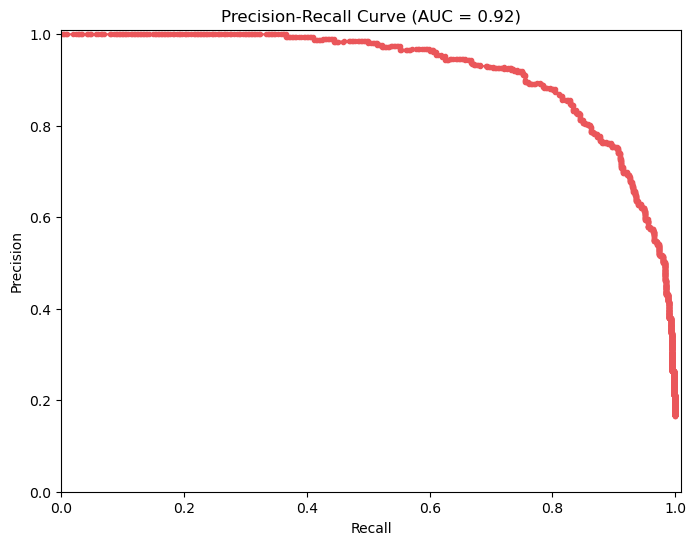

In [7]:
# Make predictions on the test set
y_pred = clf.predict_proba(X_test)[:, 1]
 
# Calculate precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_pred)
 
# Calculate the area under the PR curve
auc_score = auc(recall, precision)
 
# Plot the Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', label='PR Curve', color='#ea565aff')
plt.xlim(0, 1.01)
plt.ylim(0, 1.01)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.show()
#plt.savefig('pr_curve_3.svg')
 

In [83]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

model = XGBClassifier(
    eval_metric="logloss",
    random_state=42,
    scale_pos_weight =7
)

param_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, 12]
}

cv = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="average_precision",   # or accuracy, neg_log_loss, etc.
    cv=5,
    n_jobs=-1,
    verbose=1
    
)

cv.fit(X_train, y_train)

print("Best max_depth:", cv.best_params_["max_depth"])
print("Best CV score:", cv.best_score_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Best max_depth: 10
Best CV score: 0.8685184020090041


In [ ]:
# Define a function to calculate evaluation metrics for a given threshold
def evaluate_threshold(y_true, y_pred_proba, threshold):
    y_pred = (y_pred_proba >= threshold).astype(int)
    precision, recall, _ = precision_recall_curve(y_true, y_pred)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-7)
    balanced_accuracy = (recall[1] + recall[0]) / 2
    print("     precision    recall   f1-score ")
    print(f"0     {precision[0]:.4f}       {recall[0]:.4f}      {f1[0]:.4f}")
    print(f"1     {precision[1]:.4f}       {recall[1]:.4f}      {f1[1]:.4f}")
    print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
    return precision, recall, f1, balanced_accuracy


In [150]:
evaluate_threshold(y_test, y_pred_proba, 0.3)

     precision    recalll   f1-score 
0     0.1150       1.0000      0.2062
1     0.5720       0.8614      0.6875
Balanced Accuracy: 0.9307


(array([0.11495845, 0.572     , 1.        ]),
 array([1.        , 0.86144578, 0.        ]),
 array([0.20621116, 0.68749995, 0.        ]),
 np.float64(0.9307228915662651))

In [25]:
precisions =[]
precisions_sd = []
recalls = []
recalls_sd =[]
f1_scores = []
f1_scores_sd = []
from sklearn.metrics import f1_score
pos_weight = 15

iter = 10
for i in range(pos_weight):
    precision = []
    recall = []
    f1 = []
    for k in range(iter):
        X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)
        clf = XGBClassifier(scale_pos_weight = i+1, eval_metric='logloss')
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        # Get recall for positive class only (label=1)
        recall.append(recall_score(y_test, y_pred, pos_label=1))
        precision.append(precision_score(y_test, y_pred, pos_label=1))
        f1.append(f1_score(y_test, y_pred, pos_label=1))
    precisions.append(np.mean(np.array(precision)))
    precisions_sd.append(np.std(np.array(precision)))
    recalls.append(np.mean(np.array(recall)))
    recalls_sd.append(np.std(np.array(recall)))
    f1_scores.append(np.mean(np.array(f1)))
    f1_scores_sd.append(np.std(np.array(f1)))



In [23]:
print(f1_scores_sd)

[np.float64(0.048674321728475835), np.float64(0.02855178238536098), np.float64(0.02941580328073533), np.float64(0.03670433443735363), np.float64(0.03524226180508704), np.float64(0.03106724645176485), np.float64(0.0342592664362103), np.float64(0.02363628565787127), np.float64(0.03595755206197308), np.float64(0.04478477815356536), np.float64(0.03074396673467343), np.float64(0.024321682729249908), np.float64(0.03243233341493752), np.float64(0.03392116020836987), np.float64(0.05165047721339581)]


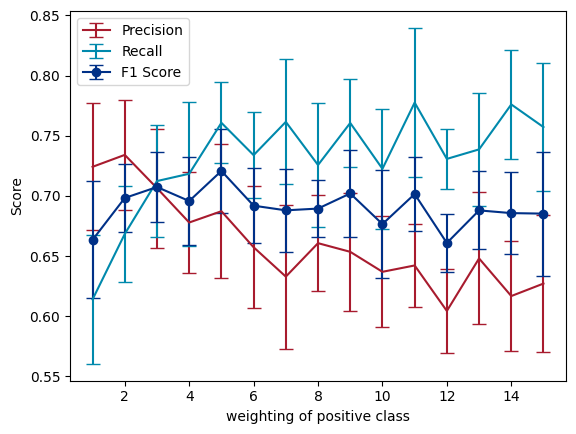

In [24]:
from matplotlib import pyplot as plt
from cycler import cycler
plt.errorbar(range(1, pos_weight+1), precisions, yerr=precisions_sd, label='Precision', capsize=5)
plt.errorbar(range(1, pos_weight+1), recalls, yerr =recalls_sd, label='Recall', capsize=5)
plt.errorbar(range(1, pos_weight+1), f1_scores, yerr=f1_scores_sd, label='F1 Score', fmt='-o', capsize=5)
plt.rc('axes', prop_cycle=cycler('color', custom_c))
plt.xlabel('weighting of positive class')
plt.ylabel('Score')
plt.legend()
#plt.show()
plt.savefig('pos_weighting.png', dpi=300)

In [15]:
np.sum(np.array(bitvectors), axis=0)

array([  20,  395,    0,  341,  318,  203,    6,   15,    0,    0,  134,
       1158,    6,  493,  585,  166,   54,   12,  835,  451,    0,   21,
        640,  124,  283,    6,    0,    0,    0,    0,    2,   96,   95,
         31,    0,  284,   66,   35,  754,  406,  308,  124,  139,    0,
         29, 1183,   86,  279,  648,  184,  187,   41,  816,  441,    0,
         19, 1083,   51,   54,    0,   37,   19,    0,    0,    1,   12,
         12,   10,    0,  344,   99,   67,  982,  294,  221,  412,   57,
          0,   36,  514,    0,    0,  214,  451,    4,    0,  314,  160,
         55,   26,    7])

In [82]:
np.array(bitvectors).shape

(1506, 91)

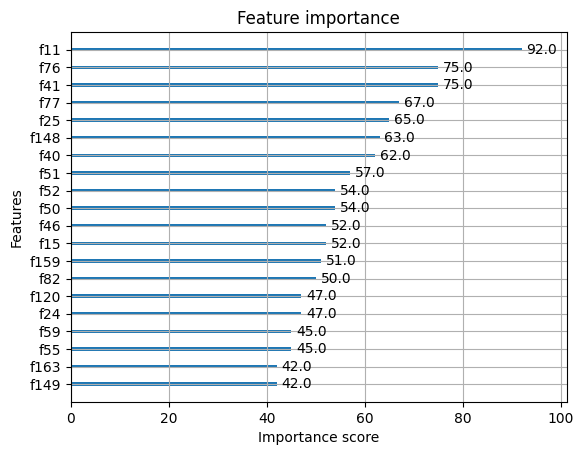

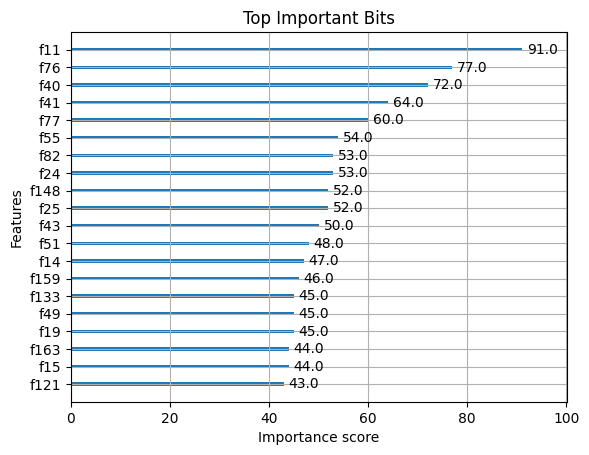

In [77]:
clf1 = XGBClassifier()
clf1.load_model('models/v14/xg_model.json')
clf2 = XGBClassifier()
clf2.load_model('models/v13/xg_model.json')
xgboost.plot_importance(clf1, max_num_features=20)
xgboost.plot_importance(clf2, max_num_features=20)
plt.title("Top Important Bits")
plt.show()

In [35]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)


clf = RandomForestClassifier(
    n_estimators=100,     # number of trees
    max_depth=None,       # let trees grow until pure
    class_weight='balanced',  # helpful for imbalanced classes
    random_state=42
)
clf.fit(X_train, y_train)

# Predict
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9521531100478469
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.97      2381
           1       0.83      0.76      0.80       336

    accuracy                           0.95      2717
   macro avg       0.90      0.87      0.89      2717
weighted avg       0.95      0.95      0.95      2717



In [41]:
%run ml_tools/get_feature.py 10

Feature at index 10: Atom 1 - Charge Bit


In [95]:
clf = xgboost.XGBClassifier()
clf.load_model('models/v12/xg_model.json')
#clf = joblib.load('models/v12/xg_model.pkl')

In [ ]:
beckmann = Chem.MolFromSmiles('[OH2+]N=C1CCCCC1')
alkyl = Chem.MolFromSmiles('CC(C)(C)[CH2+]')
tert_brom = Chem.MolFromSmiles('CC1(Br)CCCCC1')
bv = Chem.MolFromSmiles('OOC1(O)CCCCC1')
bv_p = Chem.MolFromSmiles('[OH2+]OC1(O)CCCCC1')
r_aldol = Chem.MolFromSmiles('COC(C)([O-])C(C)(C)C(C)=O')
ohira_bestman = Chem.MolFromSmiles('CC(=[C])C1=CC=CC=C1')
diazo = Chem.MolFromSmiles('N#[N+]C1=CC=CC=C1')
brook = Chem.MolFromSmiles('CC(C[O-])[Si](C)(C)C')
benzoin = Chem.MolFromSmiles('N#CC([O-])(c1ccccc1)C(O)c1ccccc1')


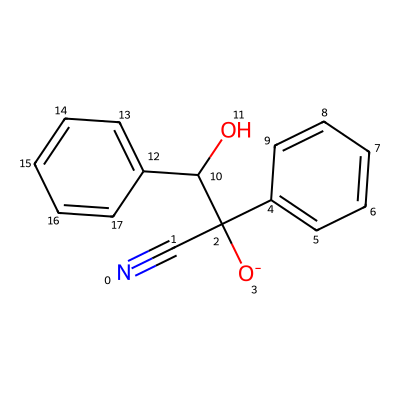

In [109]:
benzoin

In [110]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

In [120]:
clf = xgboost.XGBClassifier()
clf.load_model('models/v12/xg_model.json')
#clf = joblib.load('models/v12/xg_model.pkl')
mol = benzoin
arrow = [1, 3, 2, None, 1]
sum_finger_print = make_fingerprint(mol, arrow)

In [121]:
print(clf.predict(np.array([sum_finger_print]).reshape(1, -1)))

[1]


In [113]:
clf

,objective,'binary:logistic'
,base_score,'5.20722E-1'
,booster,'gbtree'
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [196]:
outcomes.count(1)

214

In [197]:
len(outcomes)

1506

In [199]:
(1506-214)/214

6.037383177570093

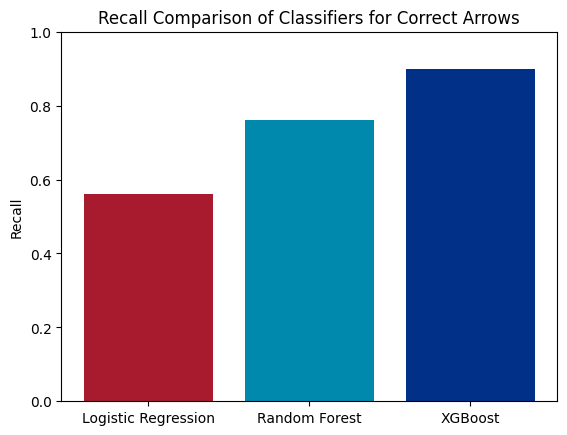

In [36]:
recalls = [0.56, 0.76, 0.90]
labels = ["Logistic Regression", "Random Forest", "XGBoost"]
plt.bar(labels, recalls, color=custom_c[:len(labels)])
plt.ylabel("Recall")
plt.title("Recall Comparison of Classifiers for Correct Arrows")
plt.ylim(0, 1)
plt.show()

In [21]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True

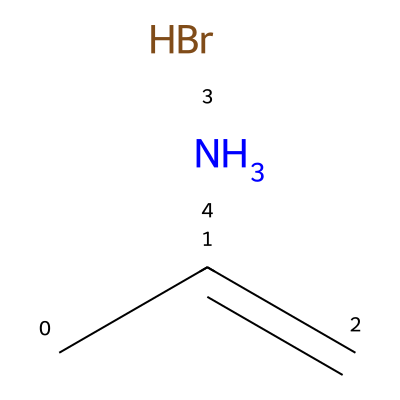

In [34]:
with open("training/20250611/144/mol_0.pkl", "rb") as f:
    debug_mol = pickle.load(f)
debug_mol

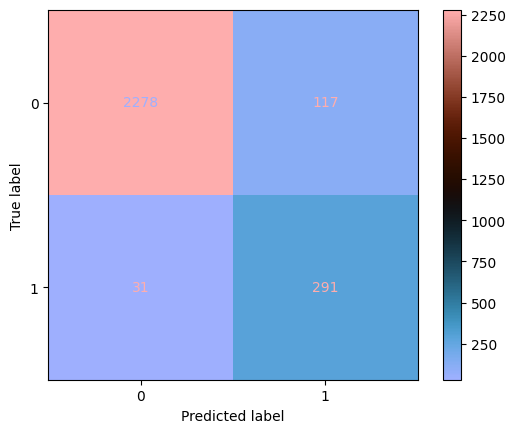

In [54]:
confmat = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=confmat, display_labels=clf.classes_)
disp.plot(cmap="berlin")
plt.savefig('confusion_matrix.svg')
plt.show()


In [61]:
training_id = 16
training_dir = os.path.join("training", str(training_id))
t_mol_objects = []

for root, dirs, files in os.walk(training_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        if file == "sm.pkl":
                            sm = mol
                        else:
                            t_mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")
    
with open(os.path.join(training_dir,'data.json'), 'r') as file:
    data = json.load(file)

t_mol_objects = [sm] + t_mol_objects

print(f"Converted {len(t_mol_objects)} pickle files to RDKit Mol objects.")
print(data)

Converted 2 pickle files to RDKit Mol objects.
{'choices': {'0': {'mechanism': [1, 2, 0, None, 1], 'probable': 1}}}


In [ ]:
reactions_dir = "reactions"
reaction_id = 5
reaction_dir = os.path.join(reactions_dir, str(reaction_id))
mol_objects = []

for root, dirs, files in os.walk(reaction_dir):
    files.sort()
    for file in files:
        if file.endswith(".pkl"):
            file_path = os.path.join(root, file)
            with open(file_path, "rb") as f:
                try:
                    mol = pickle.load(f)
                    if mol:
                        mol_objects.append(mol)
                except Exception as e:
                    print(f"Error processing {file_path}: {e}")

print(f"Converted {len(mol_objects)} pickle files to RDKit Mol objects.")


opt = Chem.Draw.MolDrawOptions()
opt.addAtomIndices = True
Chem.Draw.MolsToGridImage(mol_objects, molsPerRow=5, subImgSize=(400, 400), legends=[f"ID {i+1}" for i in range(len(mol_objects))], drawOptions=opt)

Converted 6 pickle files to RDKit Mol objects.


Can we learn chemical reactions from the reaction space

In [23]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import pairwise_distances


mask = np.array(outcomes) == 1
X = np.array(bitvectors)[mask]


# Use Jaccard distance
distances = pairwise_distances(np.array(bitvectors), metric='jaccard')

# Fit kNN using precomputed distances
#knn = NearestNeighbors(n_neighbors=2, metric='precomputed')
#knn.fit(distances)

# Find nearest neighbors of a specific vector
#dists, indices = knn.kneighbors([distances[0]])
#print("Nearest neighbors of first bitstring:", indices)

/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


In [39]:
from sklearn.cluster import DBSCAN

# Compute Jaccard distance matrix
dist = pairwise_distances(X, metric='jaccard')

# Cluster using DBSCAN
clustering = DBSCAN(metric='precomputed', eps=0.2, min_samples=3)
labels = clustering.fit_predict(dist)

print("Cluster labels:", labels)

Cluster labels: [ 0  0  1  0  1 -1 -1 -1  2 -1 -1 -1  3  3 -1 -1 -1  1  4  4  4  4  1  4
  1 -1 -1 -1 -1 -1  3 -1 -1 -1 -1 -1  5 -1  6 -1  5  7  5  8  9 10 11  7
  5 -1 -1  7 -1  5  7 -1 -1  5  7  6  6 -1 -1  5  5 -1 -1 12  5 -1 -1 -1
 -1 12  6  5 13  8  5 10 11 -1 -1 -1 -1  5  9 -1  5 -1  9 10 -1  5 13 -1
  9  7  5 -1  7 -1 -1 -1 -1 -1 -1  5 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 13 -1 -1  5 -1 -1  7 -1 -1  3  5  9  9  9  7  7  7  7  7
  7  7  7  7  7  7  8 11 -1  3  3 -1 -1 -1 -1 -1 -1 -1 -1  2 -1 -1 -1 -1
 -1 -1  2 -1  5 -1 -1 14 -1 -1 -1 14 -1 -1 -1 12 14 -1 -1 -1 -1 -1  6 -1
  5 -1 -1 -1 -1  5  9  7 -1 -1 -1 -1 -1 -1 -1  5 -1  9 -1  5  9 -1]


/home/rd611/.conda/envs/aim/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


In [40]:
len(labels)

214

In [41]:
len(bitvectors)

1506

In [42]:
from collections import defaultdict

clusters = defaultdict(list)
for idx, label in enumerate(labels):
    clusters[label].append(idx)

for cluster_id, members in clusters.items():
    if cluster_id == -1:
        print(f"Noise points: {members}")
    else:
        print(f"Cluster {cluster_id}: {members}")

Cluster 0: [0, 1, 3]
Cluster 1: [2, 4, 17, 22, 24]
Noise points: [5, 6, 7, 9, 10, 11, 14, 15, 16, 25, 26, 27, 28, 29, 31, 32, 33, 34, 35, 37, 39, 49, 50, 52, 55, 56, 61, 62, 65, 66, 69, 70, 71, 72, 81, 82, 83, 84, 87, 89, 92, 95, 99, 101, 102, 103, 104, 105, 106, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 126, 127, 129, 130, 132, 133, 152, 155, 156, 157, 158, 159, 160, 161, 162, 164, 165, 166, 167, 168, 169, 171, 173, 174, 176, 177, 178, 180, 181, 182, 185, 186, 187, 188, 189, 191, 193, 194, 195, 196, 200, 201, 202, 203, 204, 205, 206, 208, 210, 213]
Cluster 2: [8, 163, 170]
Cluster 3: [12, 13, 30, 134, 153, 154]
Cluster 4: [18, 19, 20, 21, 23]
Cluster 5: [36, 40, 42, 48, 53, 57, 63, 64, 68, 75, 78, 85, 88, 93, 98, 107, 128, 135, 172, 192, 197, 207, 211]
Cluster 6: [38, 59, 60, 74, 190]
Cluster 7: [41, 47, 51, 54, 58, 97, 100, 131, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 199]
Cluster 8: [43, 77, 150]
Cluster 9: [44, 86, 90, 96, 1

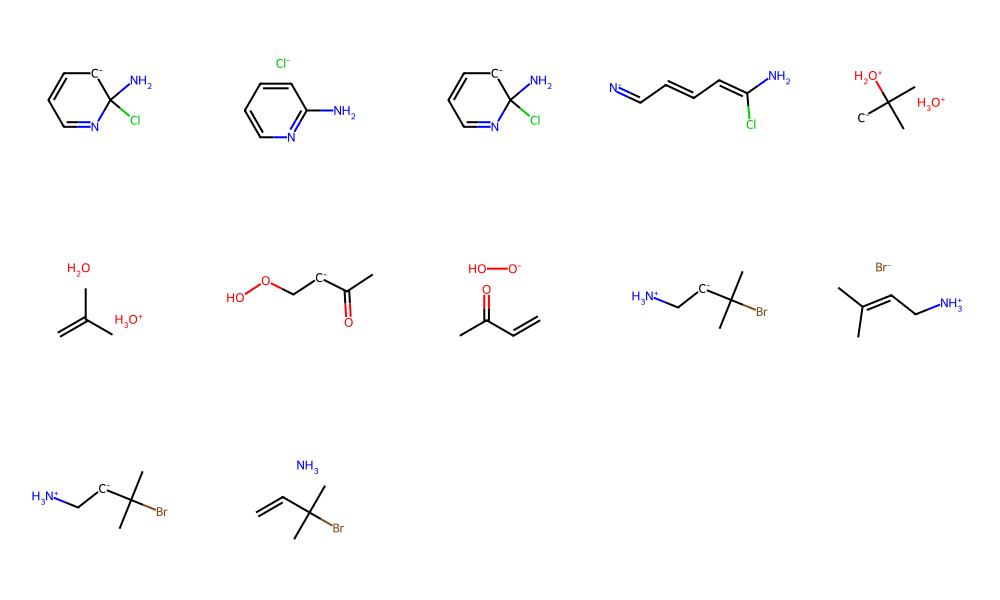

In [44]:
from rdkit.Chem import Draw

# Select a specific cluster to visualize (e.g., cluster_id)
cluster_members = clusters[3]

# For each member index, find the corresponding training directory

mols = []
legends = []
# subdirs is sorted list of training subdirectory names (as strings)
# cluster_members contains indices into the mask-filtered X (i.e., indices of probable outcomes)
# We need to map these indices back to the original subdirs

# First, get the indices of all probable outcomes in the original bitvectors list
probable_indices = np.where(mask)[0]

for idx in cluster_members:
    # Use bitvector_origins.txt to map idx to folder and choice id
    with open("bitvector_origins.txt", "r") as origin_file:
        for line in origin_file:
            parts = line.strip().split(",")
            if int(parts[0]) == probable_indices[idx]:
                folder_path = parts[1]
                subdir = os.path.basename(folder_path)
                mol_id = parts[2]
                break
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    mol_path = os.path.join(folder_path,  "mol_" + str(mol_id) + '.pkl')
    json_path = os.path.join(folder_path, 'data.json')
    # Load molecule
    with open(pkl_path, "rb") as f:
        mol = pickle.load(f)
        mols.append(mol)
    # Load probable mechanism info
    with open(mol_path, 'rb') as f:
        mol = pickle.load(f)
        mols.append(mol)
    legends.append(f"ID {subdir}")

# Visualize molecules with legends
Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(200, 200))